# 02 - EDA

We explore the *cleaned* dataset from notebook 01 to understand class balance, subject/lighting/glasses effects, image properties and relationships between variables. Every figure is saved to `images/`, and the last section writes down the key findings automatically from the data.

Target variable: `closed` (1 = closed eye, 0 = open eye).

In [1]:
import os, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from scipy.stats import chi2_contingency

sns.set_theme(style='whitegrid')
DATA_DIR = os.environ.get('MRL_DIR', '../data/raw/mrl')
PROC_DIR, IMG_DIR = '../data/processed', '../images'
os.makedirs(IMG_DIR, exist_ok=True)
def savefig(name): plt.savefig(os.path.join(IMG_DIR, name), dpi=150, bbox_inches='tight')

df = pd.read_csv(f'{PROC_DIR}/metadata_clean.csv')
df['label'] = df.closed.map({0: 'open', 1: 'closed'})
df['gender_name'] = df.gender.map({0: 'male', 1: 'female'})
df['glasses_name'] = df.glasses.map({0: 'no glasses', 1: 'glasses'})
df['lighting_name'] = df.lighting.map({0: 'bad light', 1: 'good light'})
df['reflection_name'] = df.reflections.map({0: 'none', 1: 'small', 2: 'big'})
df['sensor_name'] = 'sensor ' + df.sensor.astype(str)
print(df.shape); df.head()

(84827, 24)


,rel_path,subject,image_id,gender,glasses,eye_state,reflections,lighting,sensor,closed,...,file_kb,mean_intensity,std_intensity,brightness_outlier,label,gender_name,glasses_name,lighting_name,reflection_name,sensor_name
0,mrlEyes_2018_01\s0001\s0001_00001_0_0_0_0_0_01...,s0001,1,0,0,0,0,0,1,1,...,2.812500,70.777718,12.004408,False,closed,male,no glasses,bad light,none,sensor 1
1,mrlEyes_2018_01\s0001\s0001_00002_0_0_0_0_0_01...,s0001,2,0,0,0,0,0,1,1,...,2.673828,71.174178,10.121225,False,closed,male,no glasses,bad light,none,sensor 1
2,mrlEyes_2018_01\s0001\s0001_00003_0_0_0_0_0_01...,s0001,3,0,0,0,0,0,1,1,...,2.475586,71.344612,11.146404,False,closed,male,no glasses,bad light,none,sensor 1
3,mrlEyes_2018_01\s0001\s0001_00004_0_0_0_0_0_01...,s0001,4,0,0,0,0,0,1,1,...,2.335938,70.708580,9.470570,False,closed,male,no glasses,bad light,none,sensor 1
4,mrlEyes_2018_01\s0001\s0001_00005_0_0_0_0_0_01...,s0001,5,0,0,0,0,0,1,1,...,2.501953,71.679012,10.955606,False,closed,male,no glasses,bad light,none,sensor 1


## 1. Dataset overview

In [2]:
print('Rows:', len(df), '| Subjects:', df.subject.nunique(), '| Features:', df.shape[1])
print('\nData types:'); print(df.dtypes.to_string())
print('\nNumeric summary:'); df[['width', 'height', 'file_kb', 'mean_intensity', 'std_intensity']].describe().round(2)

Rows: 84827 | Subjects: 37 | Features: 24

Data types:
rel_path                  str
subject                   str
image_id                int64
gender                  int64
glasses                 int64
eye_state               int64
reflections             int64
lighting                int64
sensor                  int64
closed                  int64
width                   int64
height                  int64
mode                      str
format                    str
file_kb               float64
mean_intensity        float64
std_intensity         float64
brightness_outlier       bool
label                     str
gender_name               str
glasses_name              str
lighting_name             str
reflection_name           str
sensor_name               str

Numeric summary:


,width,height,file_kb,mean_intensity,std_intensity
count,84827.00,84827.00,84827.00,84827.00,84827.00
mean,93.37,93.37,3.78,88.34,18.59
std,25.48,25.48,2.29,26.63,9.86
min,52.00,52.00,0.93,21.16,3.60
25%,75.00,75.00,2.27,71.35,12.73
50%,87.00,87.00,2.99,83.72,15.16
75%,107.00,107.00,4.42,95.98,21.64
max,299.00,299.00,24.40,222.28,65.92


## 2. Class balance (target variable)
A heavily imbalanced target would make accuracy misleading and would call for class weights or resampling.

label
open      42916
closed    41911

Imbalance ratio (majority/minority): 1.02


C:\Users\Admin\AppData\Local\Temp\ipykernel_3412\1657164646.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', order=['open', 'closed'], palette=['#4c9f70', '#d9534f'], ax=ax[0])


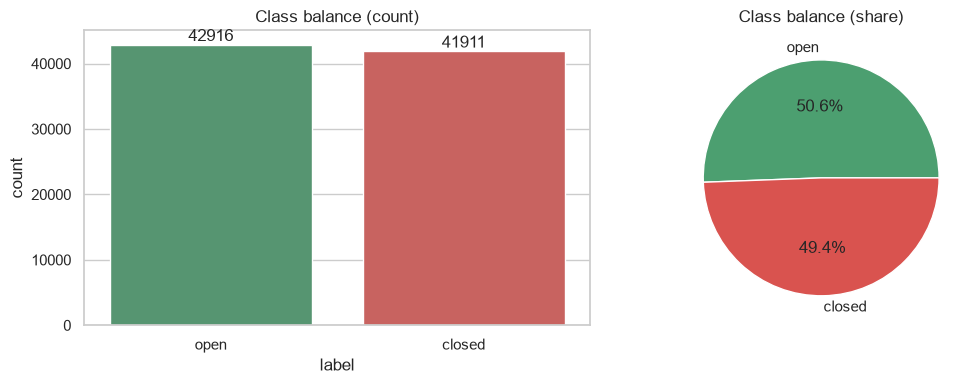

In [3]:
counts = df.label.value_counts()
ratio = counts.max() / counts.min()
print(counts.to_string()); print(f'\nImbalance ratio (majority/minority): {ratio:.2f}')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x='label', order=['open', 'closed'], palette=['#4c9f70', '#d9534f'], ax=ax[0])
for c in ax[0].containers: ax[0].bar_label(c)
ax[0].set_title('Class balance (count)')
ax[1].pie(counts[['open', 'closed']], labels=['open', 'closed'], autopct='%1.1f%%', colors=['#4c9f70', '#d9534f'])
ax[1].set_title('Class balance (share)')
plt.tight_layout(); savefig('eda_01_class_balance.png'); plt.show()

## 3. Metadata distributions
How are gender, glasses, reflections, lighting and sensor distributed? Skewed groups mean some conditions are under-represented.

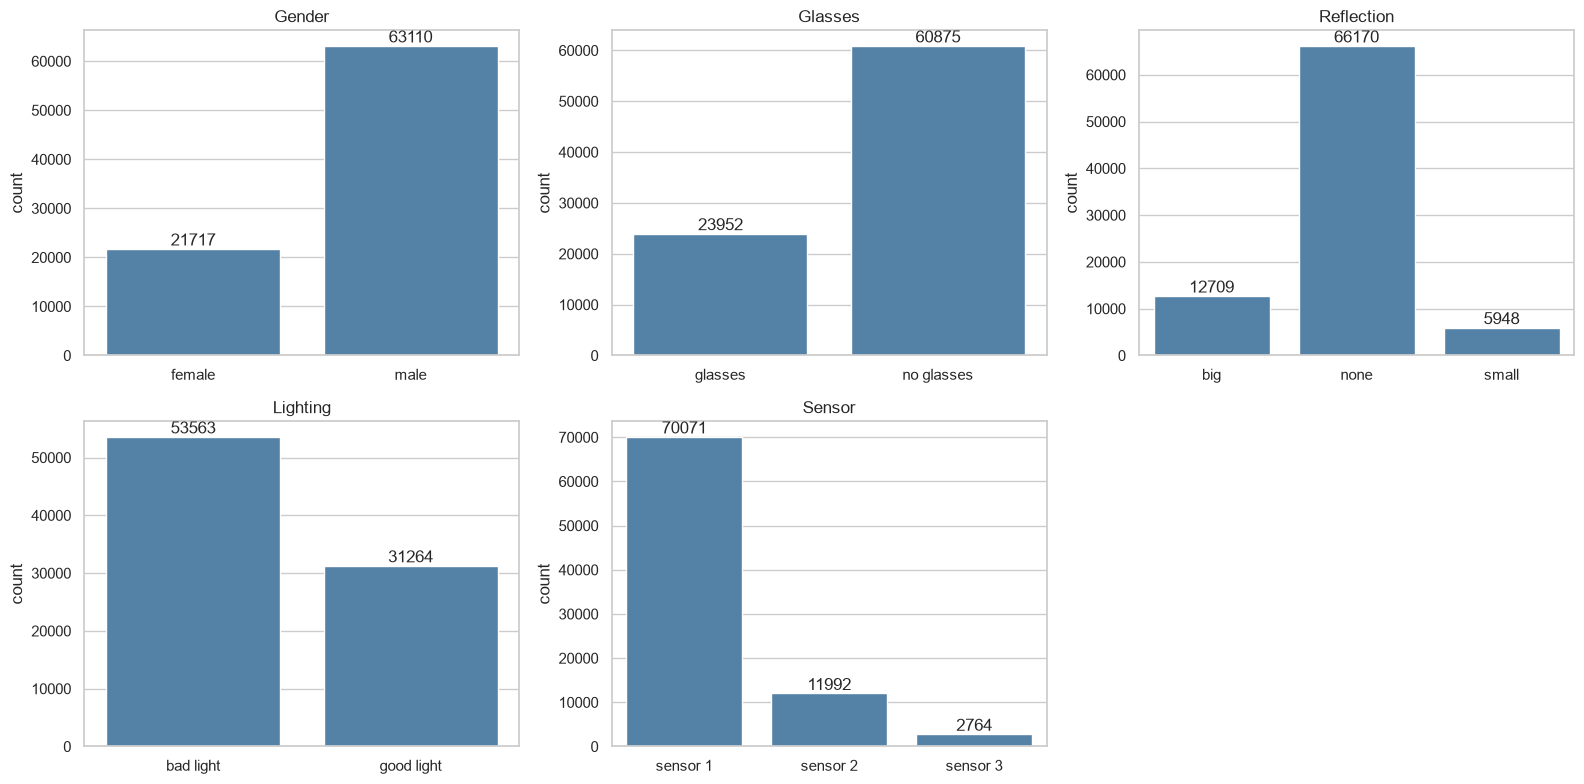

In [4]:
cats = ['gender_name', 'glasses_name', 'reflection_name', 'lighting_name', 'sensor_name']
fig, axes = plt.subplots(2, 3, figsize=(16, 8)); axes = axes.ravel()
for a, c in zip(axes, cats):
    sns.countplot(data=df, x=c, ax=a, color='steelblue', order=sorted(df[c].unique()))
    for cont in a.containers: a.bar_label(cont)
    a.set_title(c.replace('_name', '').title()); a.set_xlabel('')
axes[-1].axis('off')
plt.tight_layout(); savefig('eda_02_metadata_distributions.png'); plt.show()

## 4. Class balance inside each condition
Is the open/closed ratio the same for every gender, glasses, reflection, lighting and sensor group? If not, those variables could leak label information or bias the model.

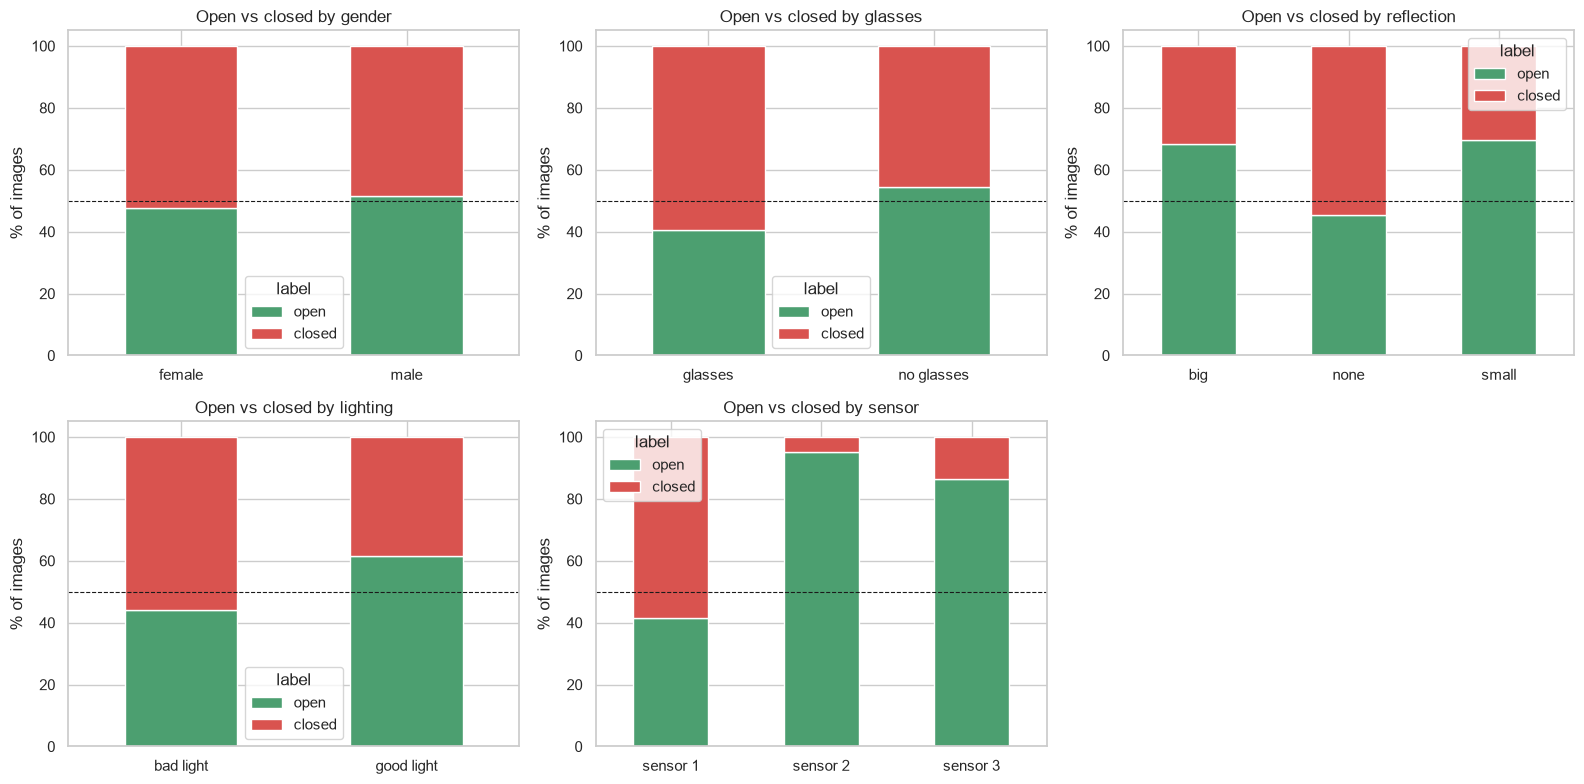

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8)); axes = axes.ravel()
for a, c in zip(axes, cats):
    ct = pd.crosstab(df[c], df.label, normalize='index')[['open', 'closed']] * 100
    ct.plot.bar(stacked=True, ax=a, color=['#4c9f70', '#d9534f'], rot=0)
    a.axhline(50, color='k', ls='--', lw=.8); a.set_ylabel('% of images'); a.set_xlabel('')
    a.set_title(f"Open vs closed by {c.replace('_name', '')}")
axes[-1].axis('off')
plt.tight_layout(); savefig('eda_03_class_by_condition.png'); plt.show()

## 5. Subjects
MRL contains many images of each person. The images of one person look alike, so train/validation/test splits **must be done by subject**, otherwise the test score will be too optimistic.

               n  closed_ratio
count     37.000        37.000
mean    2292.622         0.504
std     2658.331         0.360
min      382.000         0.018
25%      704.000         0.139
50%     1114.000         0.471
75%     1881.000         0.837
max    10257.000         1.000


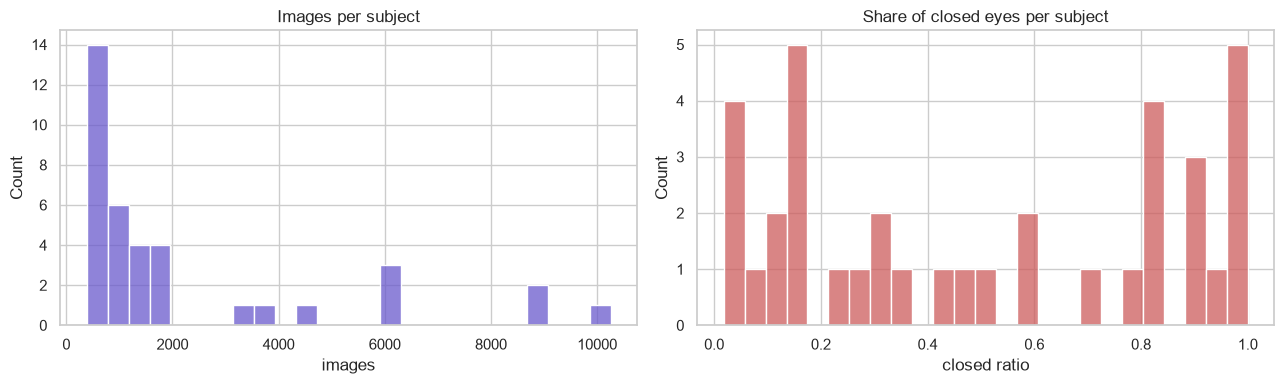

In [6]:
per_subj = df.groupby('subject').agg(n=('closed', 'size'), closed_ratio=('closed', 'mean'))
print(per_subj.describe().round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(per_subj.n, bins=25, ax=ax[0], color='slateblue'); ax[0].set_title('Images per subject'); ax[0].set_xlabel('images')
sns.histplot(per_subj.closed_ratio, bins=25, ax=ax[1], color='indianred'); ax[1].set_title('Share of closed eyes per subject')
ax[1].set_xlabel('closed ratio')
plt.tight_layout(); savefig('eda_04_subjects.png'); plt.show()

## 6. Image properties

C:\Users\Admin\AppData\Local\Temp\ipykernel_3412\2963173769.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y='mean_intensity', order=['open', 'closed'], palette=['#4c9f70', '#d9534f'], ax=ax[1, 0]); ax[1, 0].set_title('Brightness by class')


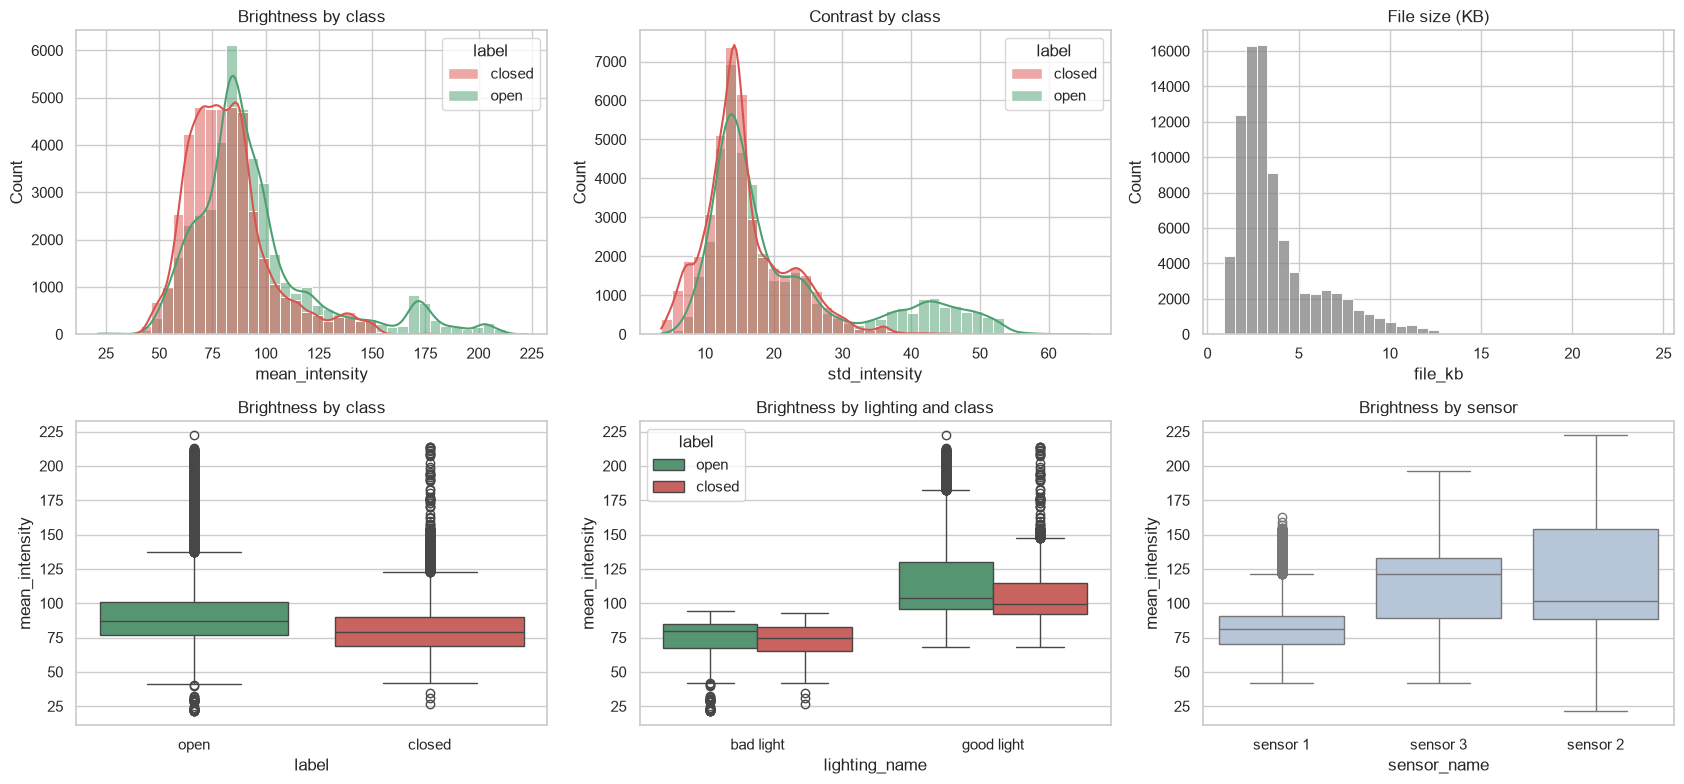

In [7]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
sns.histplot(data=df, x='mean_intensity', hue='label', bins=40, kde=True, palette=['#d9534f', '#4c9f70'], ax=ax[0, 0]); ax[0, 0].set_title('Brightness by class')
sns.histplot(data=df, x='std_intensity', hue='label', bins=40, kde=True, palette=['#d9534f', '#4c9f70'], ax=ax[0, 1]); ax[0, 1].set_title('Contrast by class')
sns.histplot(data=df, x='file_kb', bins=40, ax=ax[0, 2], color='gray'); ax[0, 2].set_title('File size (KB)')
sns.boxplot(data=df, x='label', y='mean_intensity', order=['open', 'closed'], palette=['#4c9f70', '#d9534f'], ax=ax[1, 0]); ax[1, 0].set_title('Brightness by class')
sns.boxplot(data=df, x='lighting_name', y='mean_intensity', hue='label', hue_order=['open', 'closed'], palette=['#4c9f70', '#d9534f'], ax=ax[1, 1]); ax[1, 1].set_title('Brightness by lighting and class')
sns.boxplot(data=df, x='sensor_name', y='mean_intensity', ax=ax[1, 2], color='lightsteelblue'); ax[1, 2].set_title('Brightness by sensor')
plt.tight_layout(); savefig('eda_05_brightness_contrast.png'); plt.show()

## 7. Correlation heatmap
All numeric variables, including the target `closed`.

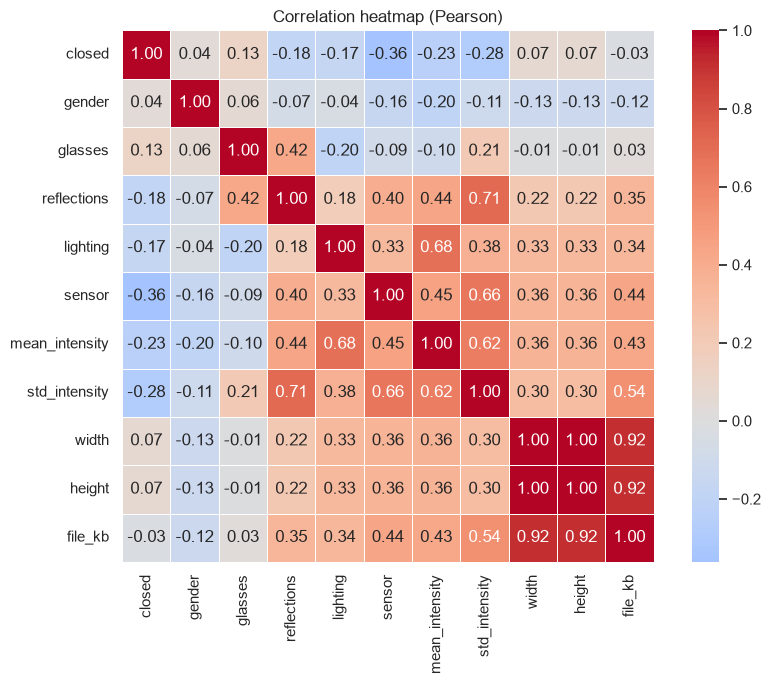

Correlation of every variable with the target (closed):
sensor           -0.361
std_intensity    -0.282
mean_intensity   -0.234
reflections      -0.182
lighting         -0.167
glasses           0.126
height            0.067
width             0.067
gender            0.036
file_kb          -0.026


In [8]:
num_cols = ['closed', 'gender', 'glasses', 'reflections', 'lighting', 'sensor',
            'mean_intensity', 'std_intensity', 'width', 'height', 'file_kb']
corr = df[num_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, linewidths=.5)
plt.title('Correlation heatmap (Pearson)')
plt.tight_layout(); savefig('eda_06_correlation_heatmap.png'); plt.show()

print('Correlation of every variable with the target (closed):')
print(corr['closed'].drop('closed').sort_values(key=abs, ascending=False).round(3).to_string())

## 8. Association of each categorical variable with the label (chi-square, Cramer's V)
Pearson correlation is not ideal for categories, so we also test independence and measure effect size.

  variable  cramers_v  p_value
    sensor     0.3952      0.0
reflection     0.1925      0.0
  lighting     0.1669      0.0
   glasses     0.1263      0.0
    gender     0.0355      0.0


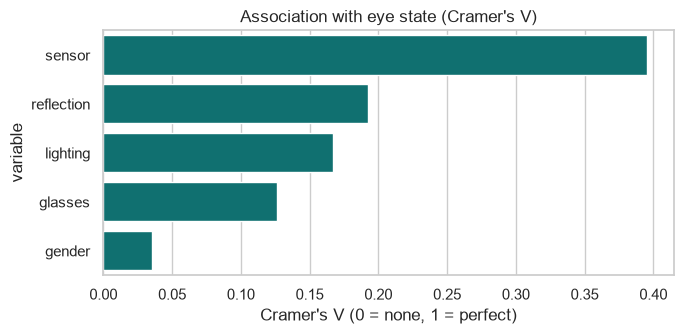

In [9]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b)
    chi2, p, _, _ = chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt((chi2 / n) / max(min(ct.shape) - 1, 1))
    return v, p

rows = [(c.replace('_name', ''), *cramers_v(df[c], df.label)) for c in cats]
assoc = pd.DataFrame(rows, columns=['variable', 'cramers_v', 'p_value']).sort_values('cramers_v', ascending=False)
print(assoc.round(4).to_string(index=False))

plt.figure(figsize=(7, 3.5))
sns.barplot(data=assoc, y='variable', x='cramers_v', color='teal')
plt.title("Association with eye state (Cramer's V)"); plt.xlabel("Cramer's V (0 = none, 1 = perfect)")
plt.tight_layout(); savefig('eda_07_cramers_v.png'); plt.show()

## 9. Looking at the images
Sample grids per class and the **mean image** of each class (average of up to 1500 images per class, resized to 64x64).

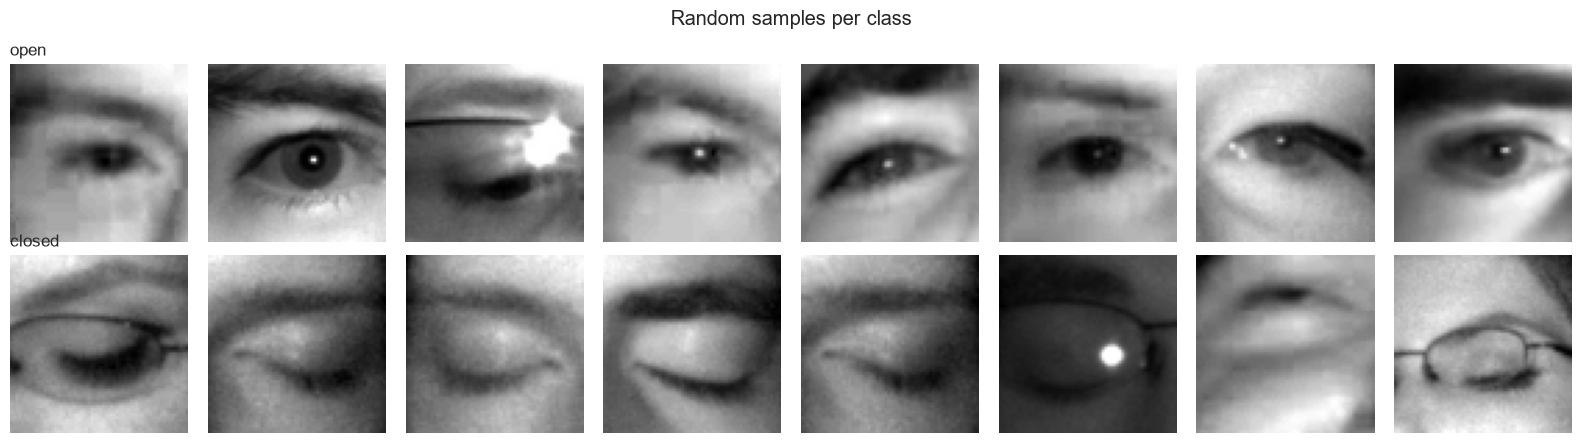

In [10]:
def load_gray(rel, size=64):
    return np.asarray(Image.open(os.path.join(DATA_DIR, rel)).convert('L').resize((size, size)), dtype=np.float32)

fig, ax = plt.subplots(2, 8, figsize=(16, 4.5))
for r, lab in enumerate(['open', 'closed']):
    sub = df[df.label == lab].sample(8, random_state=1)
    for c, rel in enumerate(sub.rel_path):
        ax[r, c].imshow(load_gray(rel), cmap='gray'); ax[r, c].axis('off')
    ax[r, 0].set_title(lab, loc='left', fontsize=12)
plt.suptitle('Random samples per class'); plt.tight_layout(); savefig('eda_08_sample_grid.png'); plt.show()

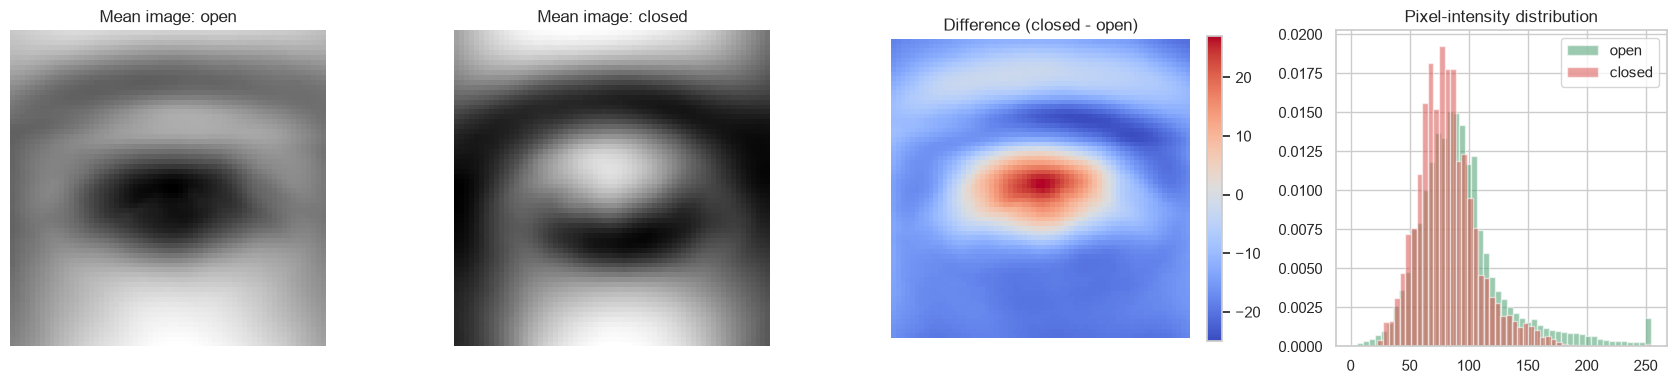

In [11]:
means, pix = {}, {}
for lab in ['open', 'closed']:
    sub = df[df.label == lab].sample(min(1500, (df.label == lab).sum()), random_state=0)
    stack = np.stack([load_gray(r) for r in sub.rel_path])
    means[lab], pix[lab] = stack.mean(0), stack.ravel()

fig, ax = plt.subplots(1, 4, figsize=(17, 4))
ax[0].imshow(means['open'], cmap='gray'); ax[0].set_title('Mean image: open')
ax[1].imshow(means['closed'], cmap='gray'); ax[1].set_title('Mean image: closed')
im = ax[2].imshow(means['closed'] - means['open'], cmap='coolwarm'); ax[2].set_title('Difference (closed - open)')
plt.colorbar(im, ax=ax[2], fraction=.046)
for lab, col in [('open', '#4c9f70'), ('closed', '#d9534f')]:
    ax[3].hist(pix[lab], bins=50, alpha=.55, density=True, color=col, label=lab)
ax[3].set_title('Pixel-intensity distribution'); ax[3].legend()
for a in ax[:3]: a.axis('off')
plt.tight_layout(); savefig('eda_09_mean_images.png'); plt.show()

In [12]:
top = corr['closed'].drop('closed').abs().idxmax()
spread = per_subj.n.max() / max(per_subj.n.min(), 1)
b_open = df[df.closed == 0].mean_intensity.mean(); b_closed = df[df.closed == 1].mean_intensity.mean()
maj = counts.idxmax()

lines = [
 f'- The cleaned dataset has {len(df):,} images from {df.subject.nunique()} subjects.',
 f"- Class balance: {counts.get('open', 0):,} open vs {counts.get('closed', 0):,} closed "
 f"(majority = {maj}, imbalance ratio {ratio:.2f}). " +
 ('The data is close to balanced; plain accuracy is acceptable but still report recall and F1 for closed eyes.'
  if ratio < 1.2 else 'The data is imbalanced: use class weights and report recall/F1/AUC.'),
 f'- Images per subject range from {per_subj.n.min()} to {per_subj.n.max()} (max/min = {spread:.1f}x), '
 'so the split must be done by subject to avoid leakage.',
 f'- Gender / glasses / reflection / lighting / sensor are all included; the variable most associated with the label is '
 f"'{assoc.iloc[0].variable}' (Cramer's V = {assoc.iloc[0].cramers_v:.3f}).",
 f"- Strongest numeric correlation with the target: '{top}' (r = {corr.loc[top, 'closed']:.3f}). "
 'Metadata and global image statistics are weak predictors, so the model must learn from the eye pixels.',
 f'- Mean brightness: open {b_open:.1f} vs closed {b_closed:.1f} (difference {abs(b_open - b_closed):.1f} grey levels on a 0-255 scale).',
 f'- Image sizes vary (width {df.width.min()}-{df.width.max()} px, height {df.height.min()}-{df.height.max()} px) '
 f'and {df.brightness_outlier.sum():,} images are brightness outliers (kept, real lighting variation).',
 '- Pixel values span 0-255, so they should be scaled to [0, 1]; all images should be converted to grayscale and resized to one fixed size.',
 '- Modeling recommendations: subject-wise train/val/test split, class weights if imbalanced, brightness augmentation, '
 'evaluate per lighting / glasses group.',
]
text = '# Key findings from EDA\n\n' + '\n'.join(lines) + '\n'
open(f'{IMG_DIR}/key_findings.md', 'w', encoding='utf-8').write(text)
print(text)

# Key findings from EDA

- The cleaned dataset has 84,827 images from 37 subjects.
- Class balance: 42,916 open vs 41,911 closed (majority = open, imbalance ratio 1.02). The data is close to balanced; plain accuracy is acceptable but still report recall and F1 for closed eyes.
- Images per subject range from 382 to 10257 (max/min = 26.9x), so the split must be done by subject to avoid leakage.
- Gender / glasses / reflection / lighting / sensor are all included; the variable most associated with the label is 'sensor' (Cramer's V = 0.395).
- Strongest numeric correlation with the target: 'sensor' (r = -0.361). Metadata and global image statistics are weak predictors, so the model must learn from the eye pixels.
- Mean brightness: open 94.5 vs closed 82.0 (difference 12.4 grey levels on a 0-255 scale).
- Image sizes vary (width 52-299 px, height 52-299 px) and 6,025 images are brightness outliers (kept, real lighting variation).
- Pixel values span 0-255, so they should be scaled to [0, 